## Project 2: Predicting Concrete Compressive Strength
## MUGANGA CHARLES B35391
DSC8307 Data Mining, Modeling and Analytics. Advent 2026 Assignment.

### What this notebook does

Compressive strength is the property engineers care about most in concrete, and the standard way to measure it is to cast a sample, wait (often 28 days) and crush it. A model that predicts strength from the recipe and the curing age could save time and material when designing mixes. This notebook follows the three tasks set in the assignment.

1. Exploring the data, writing a short report on it, preparing it with a reason for each step, and setting a mean prediction baseline.
2. Comparing linear and nonlinear models, inspecting the residuals and finding where the predictions are weakest, with evidence.
3. Discussing whether a predictive link between cement and strength tells us what would happen if we actually changed a mixture.

The notebook runs from top to bottom with the packages in `requirements.txt`, reading the data from the `data` folder. One random seed is used everywhere so the numbers quoted in the text match the outputs.

In [ ]:
# Here I am importing the libraries I need for data handling, statistics, modelling and plotting
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as st
import statsmodels.api as sm
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.outliers_influence import variance_inflation_factor

from sklearn.base import clone
from sklearn.model_selection import (GroupKFold, KFold, GroupShuffleSplit, GridSearchCV,
                                     cross_val_predict, cross_validate)
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.inspection import PartialDependenceDisplay

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 30)

# I fixed one random seed here so that every split, fold and model gives the same answer each time I run this
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

## Part 1. Understanding the data

### 1.1 Loading the file and giving the columns short names

The data was collected by Yeh (1998), who combined laboratory results from 17 different published sources. Seven columns give the amount of each ingredient in kilograms per cubic metre of concrete, one gives the age of the sample in days, and the target is compressive strength in megapascals (MPa). The original column names are long, so I give them short ones and print the mapping for traceability.

In [2]:
# Loading the data and giving the long column names short ones, printing the mapping so it stays traceable
raw = pd.read_csv("data/Concrete_Data.csv")
short_names = ["cement", "slag", "fly_ash", "water", "superplasticizer",
               "coarse_agg", "fine_agg", "age", "strength"]
print(pd.DataFrame({"original name": raw.columns, "short name": short_names}).to_string(index=False))
raw.columns = short_names
ingredients = short_names[:7]
features_raw = short_names[:8]
print()
raw.info()

                                    original name       short name
                     Cement (kg in a m^3 mixture)           cement
         Blast Furnace Slag (kg in a m^3 mixture)             slag
                    Fly Ash (kg in a m^3 mixture)          fly_ash
                      Water (kg in a m^3 mixture)            water
           Superplasticizer (kg in a m^3 mixture) superplasticizer
           Coarse Aggregate (kg in a m^3 mixture)       coarse_agg
             Fine Aggregate (kg in a m^3 mixture)         fine_agg
                                        Age (day)              age
Concrete compressive strength (MPa, megapascals)          strength

<class 'pandas.DataFrame'>
RangeIndex: 1030 entries, 0 to 1029
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   cement            1030 non-null   float64
 1   slag              1030 non-null   float64
 2   fly_ash           1030 non-null   float64

In [3]:
# Summarising every column
raw.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
cement,1030.0,281.17,104.51,102.00,192.38,272.90,350.00,540.0
slag,1030.0,73.90,86.28,0.00,0.00,22.00,142.95,359.4
fly_ash,1030.0,54.19,64.00,0.00,0.00,0.00,118.27,200.1
water,1030.0,181.57,21.36,121.75,164.90,185.00,192.00,247.0
superplasticizer,1030.0,6.20,5.97,0.00,0.00,6.35,10.16,32.2
coarse_agg,1030.0,972.92,77.75,801.00,932.00,968.00,1029.40,1145.0
fine_agg,1030.0,773.58,80.18,594.00,730.95,779.51,824.00,992.6
age,1030.0,45.66,63.17,1.00,7.00,28.00,56.00,365.0
strength,1030.0,35.82,16.71,2.33,23.71,34.44,46.14,82.6


There are 1,030 samples and no empty cells. Strength ranges from about 2 MPa to almost 83 MPa with a mean of 35.8 MPa and a standard deviation of 16.7 MPa. That standard deviation matters, because a model that always predicts the average will be wrong by roughly that much on a typical sample.

### 1.2 Zeros, duplicates and repeated recipes

In [4]:
# Counting zeros, duplicate rows and how many distinct recipes there really are
print("Zeros in each column")
print((raw == 0).sum().to_string())
print("\nExact duplicate rows:", raw.duplicated().sum())
print("Distinct recipes (same seven ingredient amounts):", raw[ingredients].drop_duplicates().shape[0])
print("Rows with the same recipe and age but a different strength:",
      raw.duplicated(subset=ingredients + ["age"]).sum() - raw.duplicated().sum())

Zeros in each column
cement                0
slag                466
fly_ash             566
water                 0
superplasticizer    379
coarse_agg            0
fine_agg              0
age                   0
strength              0

Exact duplicate rows: 25
Distinct recipes (same seven ingredient amounts): 428
Rows with the same recipe and age but a different strength: 9


In [5]:
# Checking how many rows each recipe has and how stable the total mass per cubic metre is
recipe_sizes = raw.groupby(ingredients).size()
print("How many rows does each recipe have?")
print(recipe_sizes.value_counts().sort_index().rename_axis("rows per recipe").to_frame("number of recipes").T)
print("\nTotal mass of all seven ingredients per cubic metre")
print(raw[ingredients].sum(axis=1).describe().round(1).to_string())

How many rows does each recipe have?
rows per recipe     1   2   3   4   5   6   7   8   15  20
number of recipes  246  41   8  38  76  11   3   3   1   1

Total mass of all seven ingredients per cubic metre
count    1030.0
mean     2343.5
std        65.4
min      2194.6
25%      2291.2
50%      2349.0
75%      2390.3
max      2551.0


Several points come out of this.

The zeros in slag, fly ash and superplasticizer are real. Those three are optional ingredients, and a zero means the mix simply did not contain them. They are not missing values and should not be filled in.

There are 25 rows that are exact copies of other rows. There are also 9 cases where the same recipe at the same age was tested more than once and gave different strengths, which is normal laboratory scatter and gives a feel for how much noise there is in the target.

Most importantly, the 1,030 rows come from only 428 distinct recipes. Many recipes appear several times, once for each age at which a sample was crushed (one recipe appears 20 times). This creates a hidden dependence between rows. If the same recipe is in both the training and the test data, a flexible model can memorise that recipe and look better than it really is on a new mix. I deal with this in the preparation step by splitting on recipes rather than on rows.

The total mass of the ingredients is fairly stable at around 2,200 to 2,550 kg per cubic metre, because a cubic metre of concrete can only hold so much. This physical constraint becomes important in Part 3.

### 1.3 Distributions

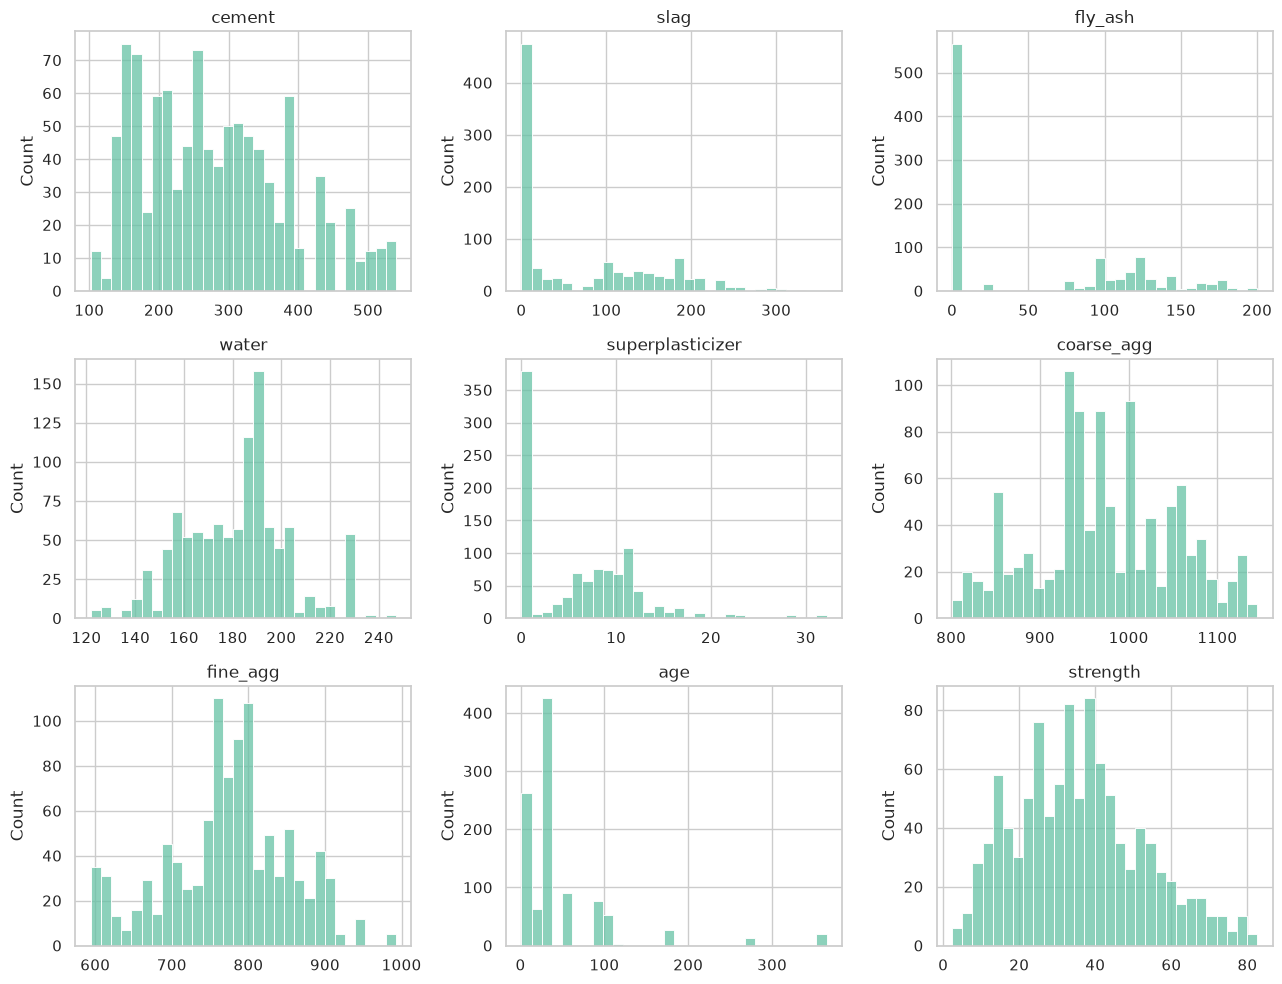

In [6]:
# Plotting the distribution of every column
fig, axes = plt.subplots(3, 3, figsize=(13, 10))
for ax, c in zip(axes.ravel(), short_names):
    sns.histplot(raw[c], ax=ax, bins=30, color="#66c2a5")
    ax.set_title(c); ax.set_xlabel("")
plt.tight_layout(); plt.show()

In [7]:
# Looking at which ages the samples were tested at
print(raw["age"].value_counts().sort_index().rename_axis("age in days").to_frame("samples").T)

age in days  1    3    7    14   28   56   90   91   100  120  180  270  360  365
samples        2  134  126   62  425   91   54   22   52    3   26   13    6   14


Strength is roughly bell shaped with a slight right skew, so no transformation of the target is needed. Age is not continuous at all. It takes only 14 distinct values, and 28 days alone accounts for 425 of the 1,030 samples, reflecting the industry habit of testing at 28 days. Ages beyond 100 days are thin, with fewer than 30 samples at each of 120, 180, 270, 360 and 365 days, so predictions for old concrete rest on little data. Superplasticizer, slag and fly ash have the spike at zero noted above.

### 1.4 Relationships with strength

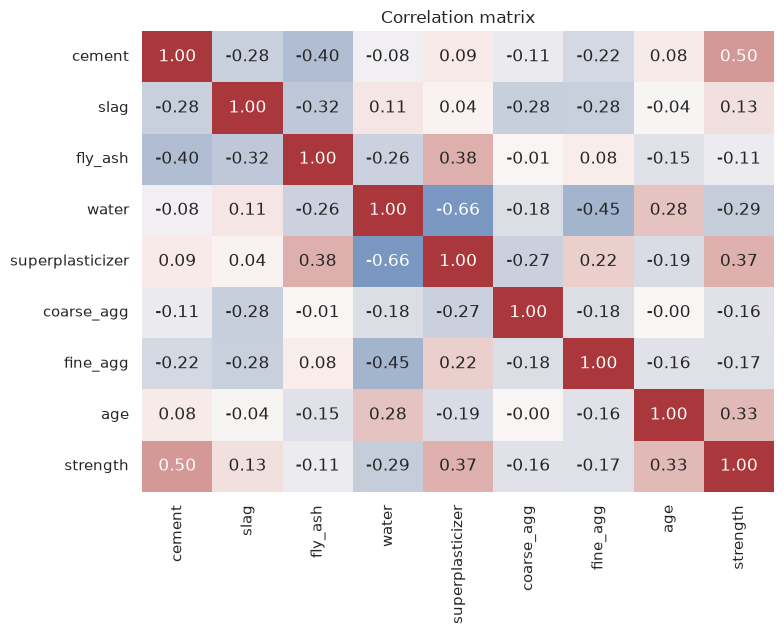

In [8]:
# Checking how the columns are correlated with each other and with strength
corr = raw.corr()
fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="vlag", center=0, ax=ax, cbar=False)
ax.set_title("Correlation matrix")
plt.tight_layout(); plt.show()

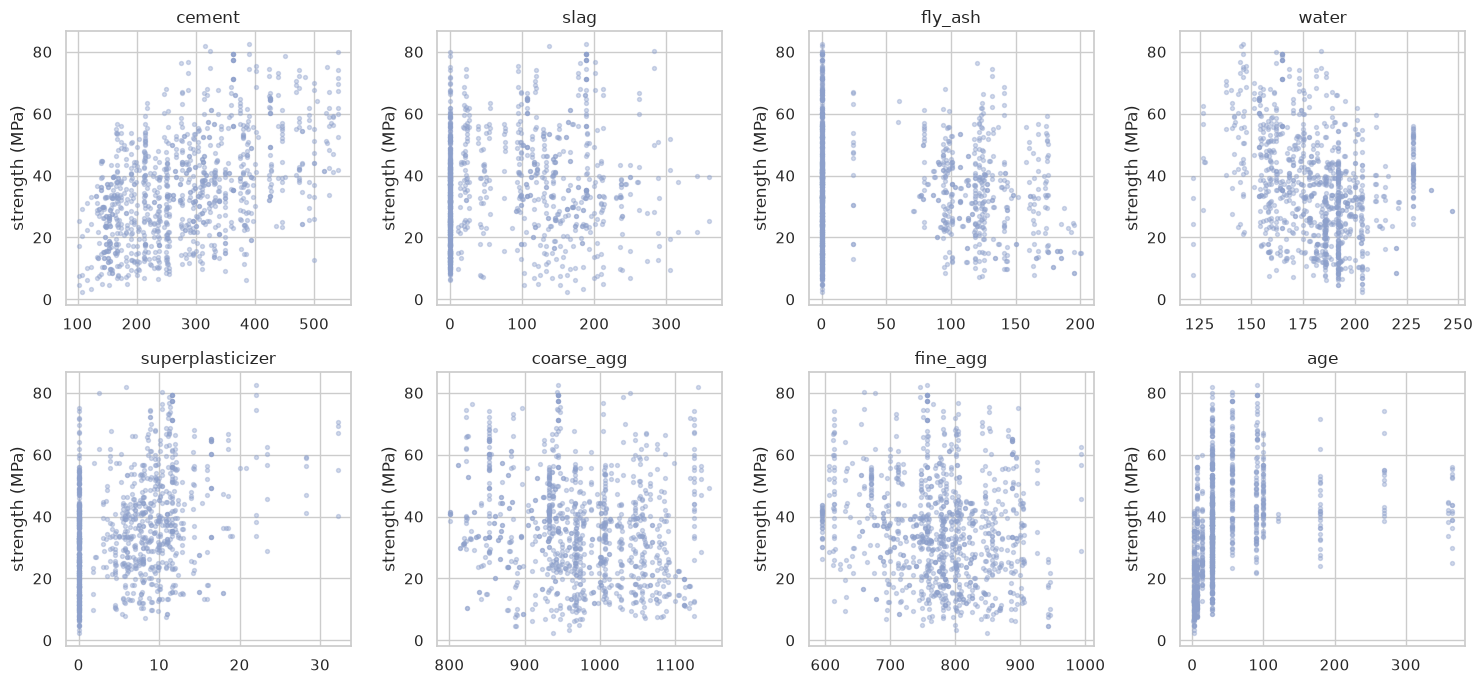

In [9]:
# Plotting strength against each input
fig, axes = plt.subplots(2, 4, figsize=(15, 7))
for ax, c in zip(axes.ravel(), features_raw):
    ax.scatter(raw[c], raw["strength"], s=8, alpha=0.4, color="#8da0cb")
    ax.set_title(c); ax.set_ylabel("strength (MPa)")
plt.tight_layout(); plt.show()

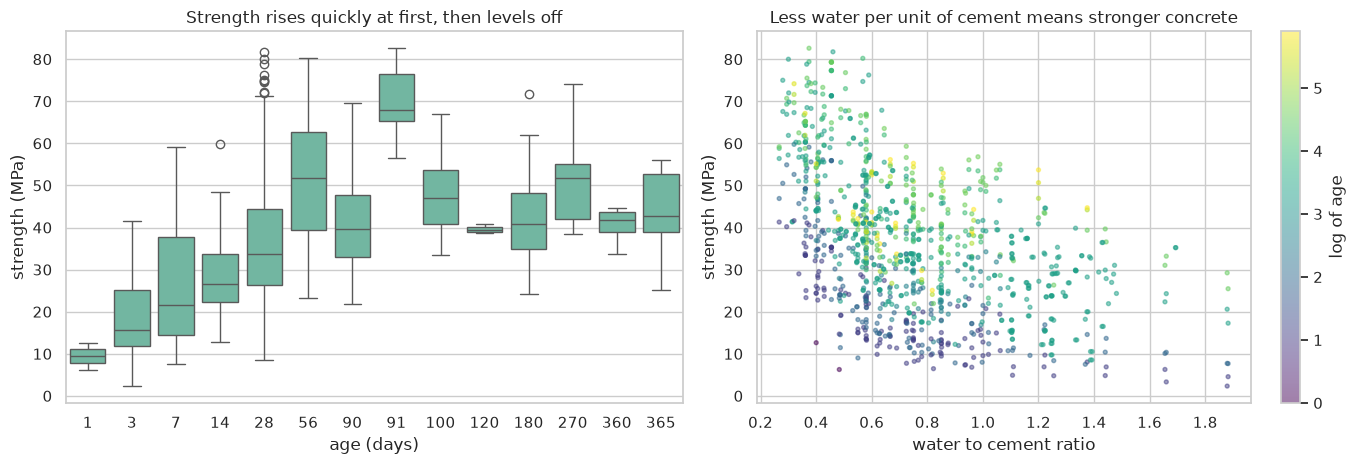

Correlation of strength with water to cement ratio: -0.501
Correlation of strength with raw age:               0.329
Correlation of strength with log of age:            0.552


In [10]:
# Looking more closely at age and at the water to cement ratio, the two relationships I expect to be curved
tmp = raw.assign(water_cement=raw["water"] / raw["cement"])
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
sns.boxplot(data=raw, x="age", y="strength", ax=axes[0], color="#66c2a5")
axes[0].set(title="Strength rises quickly at first, then levels off", xlabel="age (days)", ylabel="strength (MPa)")
sc = axes[1].scatter(tmp["water_cement"], tmp["strength"], s=8, alpha=0.5, c=np.log(tmp["age"]), cmap="viridis")
plt.colorbar(sc, ax=axes[1], label="log of age")
axes[1].set(xlabel="water to cement ratio", ylabel="strength (MPa)",
            title="Less water per unit of cement means stronger concrete")
plt.tight_layout(); plt.show()
print("Correlation of strength with water to cement ratio:", round(tmp[["water_cement", "strength"]].corr().iloc[0, 1], 3))
print("Correlation of strength with raw age:              ", round(raw[["age", "strength"]].corr().iloc[0, 1], 3))
print("Correlation of strength with log of age:           ", round(np.corrcoef(np.log(raw["age"]), raw["strength"])[0, 1], 3))

No single ingredient explains strength well. Cement has the strongest linear correlation (0.50), followed by superplasticizer (0.37) and age (0.33), while water is negatively related (minus 0.29). The scatter plots are clouds rather than lines, which already tells us that strength depends on several things at once.

Two relationships are clearly nonlinear and both are well known in concrete engineering.

First, age. Strength climbs steeply in the first four weeks and then flattens out. The correlation with strength rises from 0.33 to 0.55 when age is put on a log scale, which matches the usual description of strength gain as roughly logarithmic in time.

Second, the ratio of water to cement. Abrams (1918) showed a century ago that strength falls as this ratio rises, and the right hand plot shows exactly that falling curve, with each colour band (age) shifted up or down. The ratio correlates with strength at minus 0.50, about as strongly as cement on its own, and it captures the idea that it is the balance between water and cement that matters, not either amount alone.

The correlation matrix also shows the ingredients are related to each other. Cement is negatively correlated with slag (minus 0.28) and fly ash (minus 0.40), because these materials are commonly used to replace part of the cement. Water and superplasticizer are strongly negatively correlated (minus 0.66), because superplasticizer is added precisely so that less water is needed.

### 1.5 Short report on the data

The dataset holds 1,030 compressive strength tests on 428 distinct concrete recipes, compiled from 17 laboratory sources. Inputs are seven ingredient amounts and the curing age. The target is strength in MPa (mean 35.8, standard deviation 16.7). There are no blank values, and the zeros in slag, fly ash and superplasticizer are genuine absences.

The main limitations are as follows. There are 25 exact duplicate rows. Rows are not independent, because most recipes were tested at several ages, so validation must keep each recipe on one side of the split. Age is sampled at 14 fixed values and heavily concentrated at 28 days, with little data beyond 100 days. Very high strengths above 60 MPa are relatively rare. The ingredients are linked to each other by substitution and by the fixed volume of a cubic metre. Finally, the data does not record many things known to matter, such as the type and grade of cement, aggregate properties, curing temperature and humidity, or which laboratory did the test.

The exploration points to age (on a log scale), cement, water and the water to cement ratio, and superplasticizer as the main drivers, with clear nonlinear effects.

## Data preparation

Each step is listed with its reason.

1. I am removing the 25 exact duplicate rows. An identical row in both training and test data would be scored as if it were new.
2. I am keeping the zeros as they are. They mean "none of this ingredient was used", which is real information.
3. I am not removing outliers. The extreme values (for example 540 kg of cement or 365 days of age) are physically plausible mixes and conditions, and removing them would only hide the regions where the model struggles.
4. I am adding four engineered inputs based on concrete science: total binder (cement plus slag plus fly ash), the water to cement ratio, the water to binder ratio, and the log of age. The exploration showed the ratio and log age are far more linearly related to strength than the raw columns, so these features give a linear model a fair chance. Tree models can find such patterns themselves, but the features do no harm.
5. I am giving every distinct recipe an identifier and splitting by recipe. The held out test set (about 20 percent of rows) contains only recipes the models have never seen, and cross validation uses grouped folds for the same reason. This answers a realistic question: how well can we predict a new mix?
6. I am standardising the inputs for the linear models only, inside a pipeline so that the scaling is learned from training data alone.

In [11]:
# Step 1: I am dropping the exact duplicate rows
df = raw.drop_duplicates().reset_index(drop=True)

# Step 5 (part one): I am giving every distinct recipe its own identifier
df["mix_id"] = df.groupby(ingredients, sort=False).ngroup()

# Step 4: I am adding engineered inputs that come from concrete science
def add_features(d):
    d = d.copy()
    d["binder"] = d["cement"] + d["slag"] + d["fly_ash"]
    d["water_cement"] = d["water"] / d["cement"]
    d["water_binder"] = d["water"] / d["binder"]
    d["log_age"] = np.log(d["age"])
    return d

df = add_features(df)
features_eng = features_raw + ["binder", "water_cement", "water_binder", "log_age"]
print("Rows after removing duplicates:", len(df), " distinct recipes:", df["mix_id"].nunique())
df.head()

Rows after removing duplicates: 1005  distinct recipes: 428


,cement,slag,fly_ash,water,superplasticizer,coarse_agg,fine_agg,age,strength,mix_id,binder,water_cement,water_binder,log_age
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.986111,0,540.0,0.300000,0.30000,3.332205
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.887366,1,540.0,0.300000,0.30000,3.332205
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.269535,2,475.0,0.685714,0.48000,5.598422
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.052780,2,475.0,0.685714,0.48000,5.899897
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.296075,3,331.0,0.966767,0.58006,5.886104


In [12]:
# Step 5 (part two): I am holding out about 20 percent of the recipes as a final test set
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=RANDOM_STATE)
tr_idx, te_idx = next(gss.split(df, groups=df["mix_id"]))
train, test = df.iloc[tr_idx].copy(), df.iloc[te_idx].copy()
y_tr, y_te, g_tr = train["strength"], test["strength"], train["mix_id"]
print("Training rows:", len(train), " test rows:", len(test))
print("Recipes appearing in both parts:", len(set(train["mix_id"]) & set(test["mix_id"])))

# I am setting up grouped five fold cross validation, which I use for tuning and for comparing models
gcv = GroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

Training rows: 799  test rows: 206
Recipes appearing in both parts: 0


### 1.6 Mean prediction baseline

The baseline predicts the average training strength for every sample. Every model below is judged against it. I report root mean squared error (RMSE, in MPa, which punishes large misses), mean absolute error (MAE, in MPa, the typical miss) and R squared (the share of variation explained).

In [13]:
# Setting up a scoring helper and the mean prediction baseline
def scores(y, p):
    """Calculating RMSE, MAE and R squared for a set of predictions."""
    return {"RMSE": mean_squared_error(y, p) ** 0.5, "MAE": mean_absolute_error(y, p), "R2": r2_score(y, p)}

baseline = DummyRegressor(strategy="mean").fit(train[features_raw], y_tr)
print("Baseline always predicts", round(baseline.predict(test[features_raw].iloc[:1])[0], 2), "MPa")
base_scores = scores(y_te, baseline.predict(test[features_raw]))
pd.DataFrame([base_scores], index=["Mean baseline (test set)"]).round(3)

Baseline always predicts 34.97 MPa


,RMSE,MAE,R2
Mean baseline (test set),18.016,14.476,-0.006


The baseline misses by about 18 MPa (RMSE) on the test set, and R squared is essentially zero, as expected. Any useful model needs to come in well below 18 MPa.

## Part 2. Linear versus nonlinear models

### 2.1 The candidates

1. Linear regression on the eight raw inputs. This is the plainest model and the natural first test of whether a straight line relationship is enough.
2. Linear regression on the engineered inputs (raw inputs plus binder, the two ratios and log age). It is still a linear model, but it uses domain knowledge to straighten out the curved relationships found in the exploration. This tells us how far a linear approach can go when given help.
3. Random forest (Breiman, 2001). An average of many deep decision trees, able to capture curves and interactions without being told about them.
4. Gradient boosting (Friedman, 2001). Shallow trees added one after another, each correcting the errors of the previous ones.

The two tree models get small hyper parameter grids tuned with grouped cross validation on the training data.

In [14]:
# Defining the four candidate models, tuning the two tree models with grouped cross validation on the training data
models = {
    "Linear (raw inputs)": (Pipeline([("scale", StandardScaler()), ("model", LinearRegression())]),
                            features_raw, None),
    "Linear (engineered inputs)": (Pipeline([("scale", StandardScaler()), ("model", LinearRegression())]),
                                   features_eng, None),
    "Random forest": (RandomForestRegressor(n_estimators=500, random_state=RANDOM_STATE, n_jobs=-1),
                      features_eng, {"min_samples_leaf": [1, 3], "max_features": [0.5, 1.0]}),
    "Gradient boosting": (GradientBoostingRegressor(random_state=RANDOM_STATE, learning_rate=0.05, subsample=0.8),
                          features_eng, {"n_estimators": [300, 800], "max_depth": [3, 4]}),
}

fitted, cv_rows, fold_rmse = {}, [], {}
for name, (est, feats, grid) in models.items():
    if grid:
        search = GridSearchCV(est, grid, cv=gcv, scoring="neg_root_mean_squared_error")
        search.fit(train[feats], y_tr, groups=g_tr)
        est = search.best_estimator_
        print(f"{name:28s} best settings: {search.best_params_}")
    res = cross_validate(est, train[feats], y_tr, groups=g_tr, cv=gcv,
                         scoring=["neg_root_mean_squared_error", "neg_mean_absolute_error", "r2"])
    fold_rmse[name] = -res["test_neg_root_mean_squared_error"]
    fitted[name] = (clone(est).fit(train[feats], y_tr), feats)
    cv_rows.append({"model": name,
                    "cv RMSE": fold_rmse[name].mean(), "cv RMSE sd": fold_rmse[name].std(),
                    "cv MAE": -res["test_neg_mean_absolute_error"].mean(), "cv R2": res["test_r2"].mean()})
cv_table = pd.DataFrame(cv_rows).set_index("model")
cv_table.round(3)

Random forest                best settings: {'max_features': 0.5, 'min_samples_leaf': 1}


Gradient boosting            best settings: {'max_depth': 4, 'n_estimators': 800}


,cv RMSE,cv RMSE sd,cv MAE,cv R2
model,,,,
Linear (raw inputs),10.300,0.848,8.198,0.559
Linear (engineered inputs),6.945,0.778,5.527,0.799
Random forest,5.541,0.909,4.054,0.873
Gradient boosting,5.280,0.596,3.800,0.885


In [15]:
# Every model used the same five folds, so here I am comparing them fold by fold
fold_df = pd.DataFrame(fold_rmse, index=[f"fold {k+1}" for k in range(5)])
fold_df["GB minus RF"] = fold_df["Gradient boosting"] - fold_df["Random forest"]
fold_df["RF minus best linear"] = fold_df["Random forest"] - fold_df["Linear (engineered inputs)"]
fold_df.round(3)

,Linear (raw inputs),Linear (engineered inputs),Random forest,Gradient boosting,GB minus RF,RF minus best linear
fold 1,9.791,6.941,4.622,4.837,0.215,-2.319
fold 2,11.132,7.479,6.059,5.880,-0.179,-1.420
fold 3,9.835,6.332,5.527,5.110,-0.417,-0.804
fold 4,9.273,5.901,4.538,4.515,-0.023,-1.362
fold 5,11.471,8.072,6.960,6.057,-0.903,-1.112


### 2.2 Test set results

In [16]:
# Scoring every model on the held out test set, next to the baseline
test_pred = {name: est.predict(test[feats]) for name, (est, feats) in fitted.items()}
rows = {"Mean baseline": base_scores}
for name, p in test_pred.items():
    rows[name] = scores(y_te, p)
test_table = pd.DataFrame(rows).T
test_table.round(3)

,RMSE,MAE,R2
Mean baseline,18.016,14.476,-0.006
Linear (raw inputs),10.792,8.678,0.639
Linear (engineered inputs),7.436,5.605,0.829
Random forest,5.768,4.013,0.897
Gradient boosting,6.044,3.963,0.887


In [17]:
# I am bootstrapping the test set by resampling whole recipes, so rows from the same recipe stay together
rng = np.random.default_rng(RANDOM_STATE)
test_groups = test["mix_id"].to_numpy()
unique_groups = np.unique(test_groups)
rows_of = {g: np.where(test_groups == g)[0] for g in unique_groups}
yt = y_te.to_numpy()
boot = {n: [] for n in test_pred}
for _ in range(1000):
    pick = rng.choice(unique_groups, size=len(unique_groups), replace=True)
    idx = np.concatenate([rows_of[g] for g in pick])
    for n, p in test_pred.items():
        boot[n].append(mean_squared_error(yt[idx], p[idx]) ** 0.5)
boot = pd.DataFrame(boot)
print("Test RMSE with 95 percent bootstrap interval")
print(pd.DataFrame({"RMSE": test_table.loc[list(test_pred), "RMSE"],
                    "lower 2.5%": boot.quantile(0.025), "upper 97.5%": boot.quantile(0.975)}).round(2))

gaps = pd.DataFrame({
    "Linear raw minus Linear engineered": boot["Linear (raw inputs)"] - boot["Linear (engineered inputs)"],
    "Linear engineered minus Random forest": boot["Linear (engineered inputs)"] - boot["Random forest"],
    "Linear engineered minus Gradient boosting": boot["Linear (engineered inputs)"] - boot["Gradient boosting"],
    "Random forest minus Gradient boosting": boot["Random forest"] - boot["Gradient boosting"],
})
print("\nBootstrap distribution of RMSE gaps (positive means the second model is better)")
print(pd.DataFrame({"mean gap": gaps.mean(), "lower 2.5%": gaps.quantile(0.025),
                    "upper 97.5%": gaps.quantile(0.975), "share above zero": (gaps > 0).mean()}).round(2))

Test RMSE with 95 percent bootstrap interval
                             RMSE  lower 2.5%  upper 97.5%
Linear (raw inputs)         10.79        9.71        11.92
Linear (engineered inputs)   7.44        6.29         8.69
Random forest                5.77        4.69         6.98
Gradient boosting            6.04        4.81         7.29

Bootstrap distribution of RMSE gaps (positive means the second model is better)
                                           mean gap  lower 2.5%  upper 97.5%  share above zero
Linear raw minus Linear engineered             3.36        2.74         3.98              1.00
Linear engineered minus Random forest          1.64        0.76         2.68              1.00
Linear engineered minus Gradient boosting      1.36        0.15         2.61              0.98
Random forest minus Gradient boosting         -0.28       -0.84         0.26              0.16


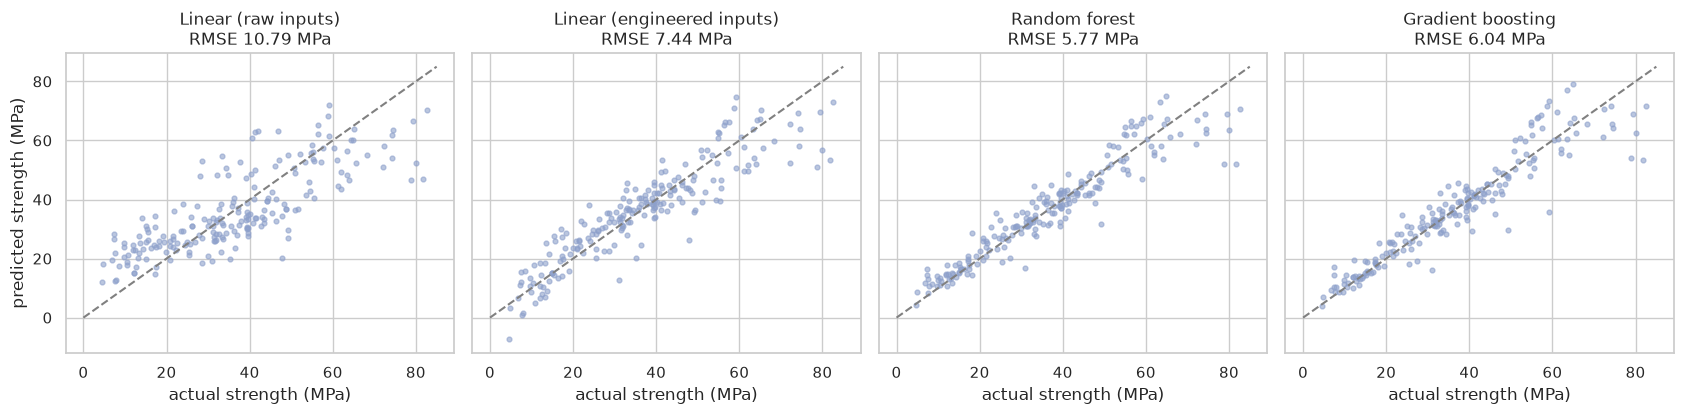

In [18]:
# Plotting predicted against actual strength for each model
fig, axes = plt.subplots(1, 4, figsize=(17, 4.3), sharex=True, sharey=True)
for ax, (name, p) in zip(axes, test_pred.items()):
    ax.scatter(y_te, p, s=12, alpha=0.6, color="#8da0cb")
    ax.plot([0, 85], [0, 85], ls="--", c="grey")
    ax.set(title=f"{name}\nRMSE {scores(y_te, p)['RMSE']:.2f} MPa", xlabel="actual strength (MPa)")
axes[0].set_ylabel("predicted strength (MPa)")
plt.tight_layout(); plt.show()

The comparison is clear and consistent across every view.

All four models beat the baseline by a wide margin.

The plain linear model cuts the error from about 18 MPa to about 10.8 MPa on the test set and explains about 64 percent of the variation. Adding the engineered features lowers the error to about 7.4 MPa and lifts R squared to 0.83. That improvement is large and it comes purely from expressing the known nonlinear science (log age, water to cement ratio) in a form a straight line can use.

The nonlinear models do better still. On the test set the random forest reaches an RMSE of about 5.8 MPa (R squared 0.90) and gradient boosting about 6.0 MPa (R squared 0.89), although gradient boosting has the slightly lower typical error (MAE 3.96 against 4.01 MPa). In grouped cross validation, which uses all 799 training rows rather than one test set of 206, gradient boosting is ahead (5.28 against 5.54 MPa), winning four of the five folds, and its fold to fold spread is the smallest of all four models.

The bootstrap, which resamples whole recipes, shows that the random forest beats the best linear model in every resample and gradient boosting does so in 98 percent of them, so the advantage of the nonlinear models is real. The gap between the two tree models is a different story: its interval runs from about minus 0.8 to plus 0.3 MPa, so the test set cannot separate them. They are effectively tied. I use gradient boosting as the reference nonlinear model below because it did better and more consistently in cross validation, but either would be a reasonable choice.

### 2.3 Sensitivity check: what happens if recipes are allowed to leak across folds?

In [19]:
# Comparing ordinary random folds with folds grouped by recipe, to see how much leakage flatters each model
kf = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
leak_rows = []
for name, (est, feats) in fitted.items():
    rand = -cross_validate(clone(est), df[feats], df["strength"], cv=kf,
                           scoring="neg_root_mean_squared_error")["test_score"].mean()
    grp = -cross_validate(clone(est), df[feats], df["strength"], groups=df["mix_id"], cv=gcv,
                          scoring="neg_root_mean_squared_error")["test_score"].mean()
    leak_rows.append({"model": name, "RMSE, random folds": rand, "RMSE, folds grouped by recipe": grp,
                      "optimism of random folds (%)": 100 * (grp - rand) / grp})
pd.DataFrame(leak_rows).set_index("model").round(2)

,"RMSE, random folds","RMSE, folds grouped by recipe",optimism of random folds (%)
model,,,
Linear (raw inputs),10.34,10.38,0.44
Linear (engineered inputs),6.92,6.98,0.82
Random forest,4.48,5.26,14.75
Gradient boosting,3.77,4.95,23.95


This check supports the decision to split by recipe. For the two linear models it makes almost no difference whether recipes are kept together, because a straight line cannot memorise a recipe. For the tree models, ordinary random folds make the error look about 15 to 24 percent smaller than it really is on unseen recipes. Many published results on this dataset use random splits, so their tree model errors are likely to be on the optimistic side. Our grouped numbers are the honest ones for designing a new mix.

### 2.4 Checking the linear model's assumptions

Ordinary least squares assumes a straight line relationship, constant error spread, roughly normal errors and inputs that are not too strongly related to each other. Fitting the plain model with statsmodels lets me test these directly.

In [20]:
# Fitting the plain linear model in statsmodels so I can test its assumptions directly
ols = sm.OLS(y_tr, sm.add_constant(train[features_raw])).fit()
print(ols.summary().tables[1])
bp_stat, bp_p, _, _ = het_breuschpagan(ols.resid, ols.model.exog)
jb_stat, jb_p = st.jarque_bera(ols.resid)
Xv = sm.add_constant(train[features_raw])
vif = pd.Series([variance_inflation_factor(Xv.values, i) for i in range(1, Xv.shape[1])], index=features_raw)
print(f"\nBreusch Pagan test for constant variance: p = {bp_p:.2e}")
print(f"Jarque Bera test for normal residuals:    p = {jb_p:.3f}")
print("Variance inflation factors:")
print(vif.round(1).to_string())

                       coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------
const              -24.4578     29.259     -0.836      0.403     -81.892      32.977
cement               0.1152      0.009     12.480      0.000       0.097       0.133
slag                 0.0988      0.011      8.949      0.000       0.077       0.120
fly_ash              0.0804      0.014      5.948      0.000       0.054       0.107
water               -0.1421      0.044     -3.198      0.001      -0.229      -0.055
superplasticizer     0.3856      0.106      3.630      0.000       0.177       0.594
coarse_agg           0.0188      0.010      1.799      0.072      -0.002       0.039
fine_agg             0.0212      0.012      1.798      0.072      -0.002       0.044
age                  0.1059      0.006     18.493      0.000       0.095       0.117

Breusch Pagan test for constant variance: p = 1.20e-19
Jarque Be

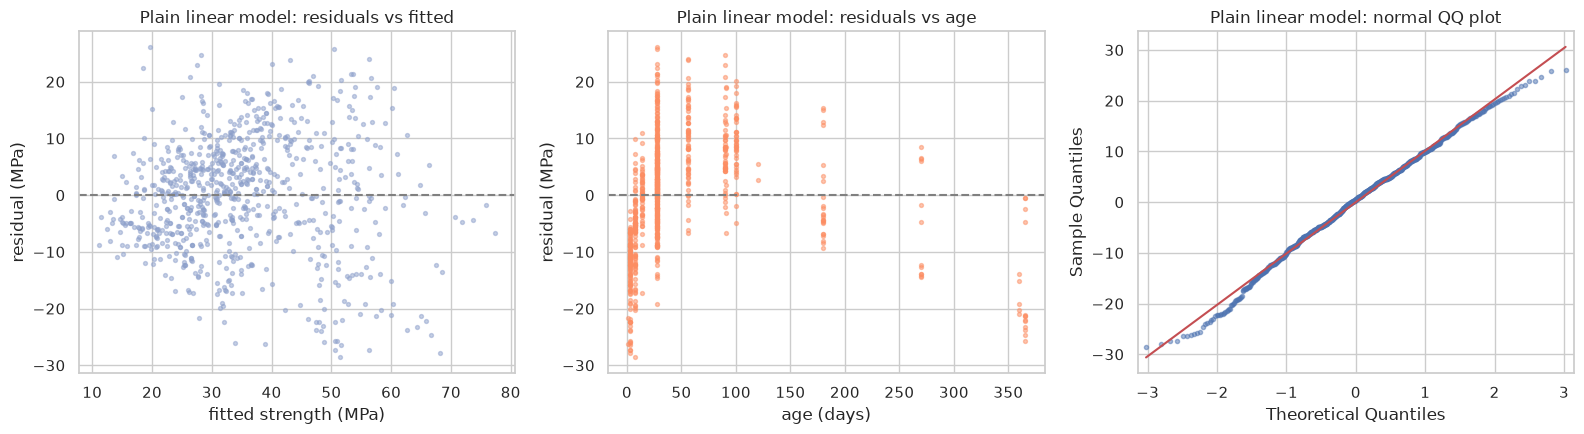

In [21]:
# Plotting the residuals of the plain linear model
lin_eng_ols = sm.OLS(y_tr, sm.add_constant(train[features_eng])).fit()
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
axes[0].scatter(ols.fittedvalues, ols.resid, s=8, alpha=0.5, color="#8da0cb")
axes[0].axhline(0, c="grey", ls="--")
axes[0].set(title="Plain linear model: residuals vs fitted", xlabel="fitted strength (MPa)", ylabel="residual (MPa)")
axes[1].scatter(train["age"], ols.resid, s=8, alpha=0.5, color="#fc8d62")
axes[1].axhline(0, c="grey", ls="--")
axes[1].set(title="Plain linear model: residuals vs age", xlabel="age (days)", ylabel="residual (MPa)")
sm.qqplot(ols.resid, line="s", ax=axes[2], markersize=3, alpha=0.5)
axes[2].set_title("Plain linear model: normal QQ plot")
plt.tight_layout(); plt.show()

The checks show why the plain linear model falls short.

The residuals against age form a clear curve: the model overpredicts young concrete, underpredicts in the middle and overpredicts old concrete, which is the signature of a straight line forced through a curved, levelling off growth pattern. The Breusch Pagan test strongly rejects constant variance (p far below 0.001), so the errors grow with the predicted strength. The QQ plot is close to the line in the middle with mild departures in the tails, and the Jarque Bera test only just rejects normality, so non normal errors are a minor issue compared with the wrong shape. Variance inflation factors between about 5 and 7.5 for most ingredients show moderate overlap between them (the substitution effect from Part 1), which makes individual coefficients less reliable but does not hurt prediction much.

The engineered linear model fixes much of the curvature problem, but it still cannot capture interactions such as the fact that slag and fly ash contribute little at early ages and much more later. That is the gap the tree models close.

### 2.5 Where are the predictions weakest?

For an honest picture across the whole dataset, I generate out of fold predictions for every row using grouped five fold cross validation. Each sample is therefore predicted by a model that never saw its recipe. I then look at the residuals (actual minus predicted) for the best linear model and for gradient boosting.

In [22]:
# Getting out of fold predictions for every row, each one from a model that never saw that recipe
oof = {}
for name in ["Linear (engineered inputs)", "Gradient boosting"]:
    est, feats = fitted[name]
    oof[name] = cross_val_predict(clone(est), df[feats], df["strength"], groups=df["mix_id"], cv=gcv)

resid = df[["mix_id", "age", "strength", "cement", "slag", "fly_ash", "water",
            "superplasticizer", "water_cement"]].copy()
resid["pred_gb"] = oof["Gradient boosting"]
resid["resid_gb"] = resid["strength"] - resid["pred_gb"]
resid["pred_lin"] = oof["Linear (engineered inputs)"]
resid["resid_lin"] = resid["strength"] - resid["pred_lin"]
resid["age group"] = pd.cut(resid["age"], [0, 3, 7, 28, 90, 365],
                            labels=["1 to 3 days", "7 days", "14 to 28 days", "56 to 91 days", "100 to 365 days"])
resid["strength band"] = pd.cut(resid["strength"], [0, 20, 40, 60, 90],
                                labels=["below 20 MPa", "20 to 40 MPa", "40 to 60 MPa", "above 60 MPa"])
print("Out of fold RMSE, gradient boosting:", round(mean_squared_error(resid.strength, resid.pred_gb) ** 0.5, 2),
      " best linear:", round(mean_squared_error(resid.strength, resid.pred_lin) ** 0.5, 2))

Out of fold RMSE, gradient boosting: 5.01  best linear: 7.02


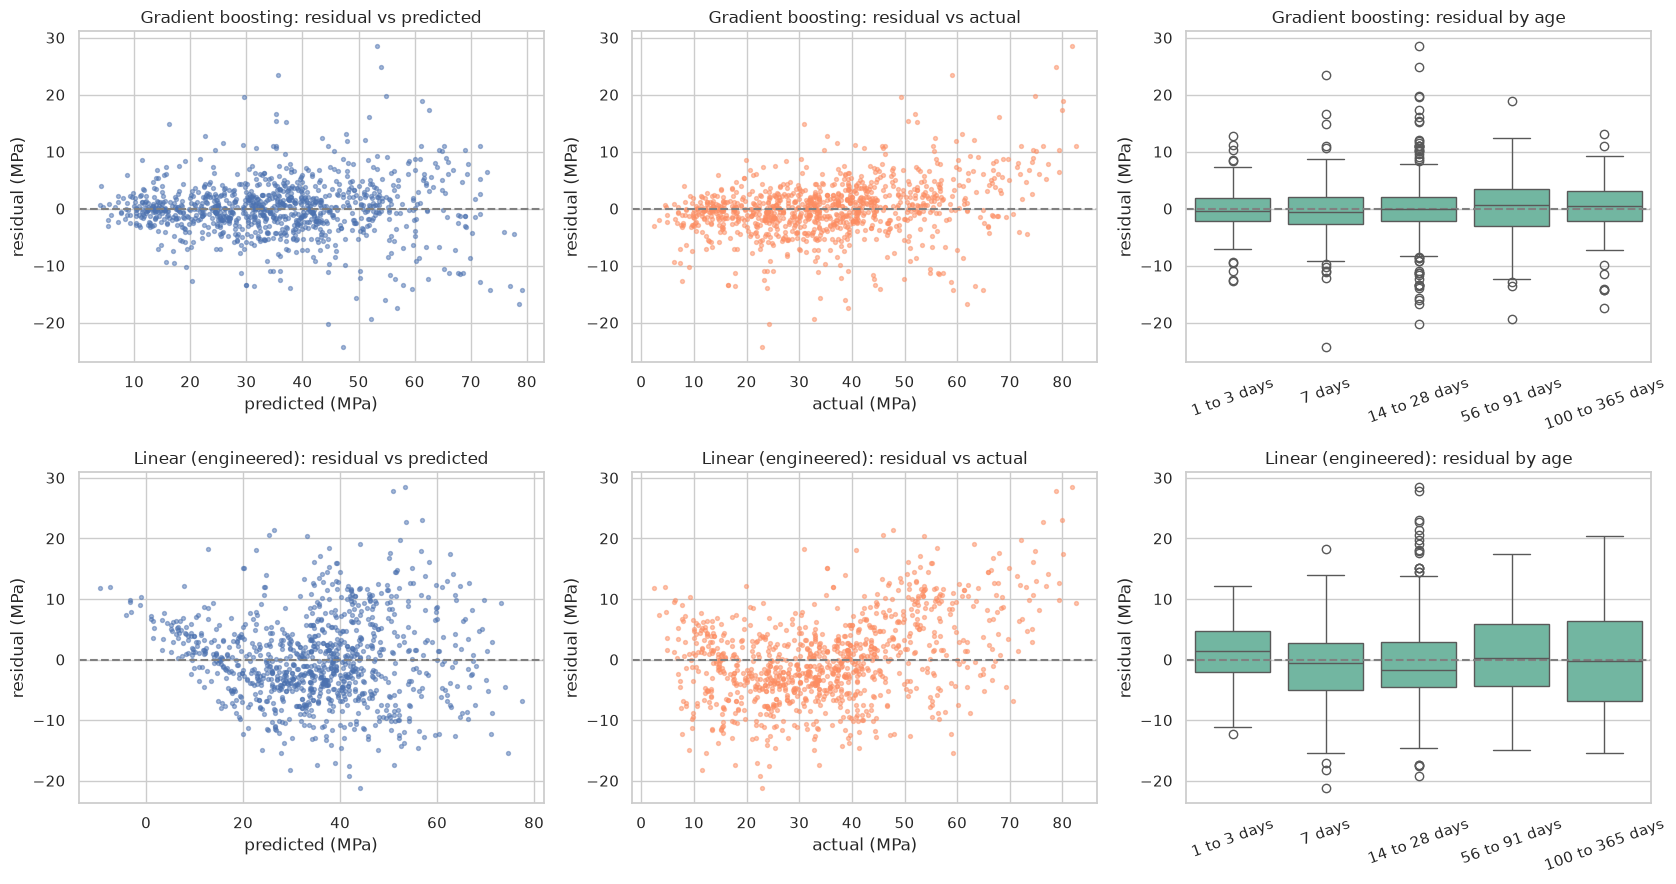

In [23]:
# Plotting residuals against predicted values, actual values and age for both models
fig, axes = plt.subplots(2, 3, figsize=(17, 9))
for row, (tag, label) in enumerate([("gb", "Gradient boosting"), ("lin", "Linear (engineered)")]):
    r = resid[f"resid_{tag}"]
    axes[row, 0].scatter(resid[f"pred_{tag}"], r, s=8, alpha=0.5)
    axes[row, 0].axhline(0, c="grey", ls="--")
    axes[row, 0].set(title=f"{label}: residual vs predicted", xlabel="predicted (MPa)", ylabel="residual (MPa)")
    axes[row, 1].scatter(resid["strength"], r, s=8, alpha=0.5, color="#fc8d62")
    axes[row, 1].axhline(0, c="grey", ls="--")
    axes[row, 1].set(title=f"{label}: residual vs actual", xlabel="actual (MPa)", ylabel="residual (MPa)")
    sns.boxplot(x=resid["age group"], y=r, ax=axes[row, 2], color="#66c2a5")
    axes[row, 2].axhline(0, c="grey", ls="--")
    axes[row, 2].set(title=f"{label}: residual by age", xlabel="", ylabel="residual (MPa)")
    axes[row, 2].tick_params(axis="x", rotation=20)
plt.tight_layout(); plt.show()

In [24]:
# Breaking the errors down by strength band and by age group
def error_table(by):
    return resid.groupby(by, observed=True).agg(
        samples=("resid_gb", "size"),
        **{"GB mean abs error": ("resid_gb", lambda r: r.abs().mean()),
           "GB average bias": ("resid_gb", "mean"),
           "Linear mean abs error": ("resid_lin", lambda r: r.abs().mean()),
           "Linear average bias": ("resid_lin", "mean")})

print("Errors by strength band (bias above zero means the model predicts too low)")
print(error_table("strength band").round(2))
print("\nErrors by age group")
print(error_table("age group").round(2))

Errors by strength band (bias above zero means the model predicts too low)
               samples  GB mean abs error  GB average bias  Linear mean abs error  Linear average bias
strength band                                                                                         
below 20 MPa       196               2.30            -1.16                   4.99                -1.35
20 to 40 MPa       449               3.14            -0.92                   4.54                -2.46
40 to 60 MPa       281               3.74             0.99                   6.32                 2.57
above 60 MPa        79               6.86             4.71                   9.13                 7.82

Errors by age group
                 samples  GB mean abs error  GB average bias  Linear mean abs error  Linear average bias
age group                                                                                               
1 to 3 days          131               3.00            -0.20                

In [25]:
# Checking whether mixes with superplasticizer, slag or fly ash are harder to predict
resid["uses superplasticizer"] = np.where(resid["superplasticizer"] > 0, "yes", "no")
resid["uses slag or fly ash"] = np.where((resid["slag"] > 0) | (resid["fly_ash"] > 0), "yes", "no")
print(error_table("uses superplasticizer").round(2))
print()
print(error_table("uses slag or fly ash").round(2))

                       samples  GB mean abs error  GB average bias  Linear mean abs error  Linear average bias
uses superplasticizer                                                                                         
no                         378               2.65            -0.02                   5.53                -0.84
yes                        627               3.91             0.03                   5.45                 0.46

                      samples  GB mean abs error  GB average bias  Linear mean abs error  Linear average bias
uses slag or fly ash                                                                                         
no                        231               2.98             0.01                   4.95                -1.18
yes                       774               3.57             0.01                   5.64                 0.32


In [26]:
# Pulling out the ten largest gradient boosting errors to see what those mixes have in common
cols = ["age", "cement", "slag", "fly_ash", "water", "superplasticizer", "water_cement", "strength", "pred_gb", "resid_gb"]
resid.reindex(resid["resid_gb"].abs().sort_values(ascending=False).index)[cols].head(10).round(2)

,age,cement,slag,fly_ash,water,superplasticizer,water_cement,strength,pred_gb,resid_gb
357,28,315.00,137.00,0.00,145.00,5.90,0.46,81.75,53.27,28.48
359,28,451.00,0.00,0.00,165.00,11.25,0.37,78.80,54.02,24.78
105,7,362.60,189.00,0.00,164.90,11.60,0.45,22.90,47.24,-24.34
104,7,389.90,189.00,0.00,145.90,22.00,0.37,59.09,35.72,23.37
202,28,167.95,42.08,163.83,121.75,5.72,0.72,24.24,44.51,-20.27
119,28,323.70,282.80,0.00,183.80,10.30,0.57,74.70,54.87,19.82
371,28,200.00,200.00,0.00,190.00,0.00,0.95,49.25,29.59,19.66
203,56,167.95,42.08,163.83,121.75,5.72,0.72,32.85,52.20,-19.35
137,56,323.70,282.80,0.00,183.80,10.30,0.57,80.20,61.30,18.90
204,100,167.95,42.08,163.83,121.75,5.72,0.72,39.23,56.76,-17.53


The residual analysis points to several clear weak spots.

1. High strength concrete. This is the biggest weakness for both model types. Above 60 MPa the gradient boosting model's mean absolute error is about 6.9 MPa, roughly three times its error below 20 MPa (2.3 MPa), and it underpredicts by about 4.7 MPa on average. The linear model is worse, underpredicting by about 7.8 MPa. The residual against actual plot shows the familiar pattern of pulling extreme values towards the middle. There are only 79 samples above 60 MPa, so the models have little to learn from at that end, and high strength mixes depend on factors the data does not record well, such as cement grade.

2. Error grows with strength. In both residual against predicted plots the spread widens as predictions increase, confirming the Breusch Pagan result. A single plus or minus figure for accuracy is therefore misleading. The model is much more precise for ordinary concrete than for high performance concrete. The linear model also shows a tilted pattern in residual against actual (too high for weak samples, too low for strong ones), and for a handful of very young, low cement samples it even predicts a negative strength, which is physically impossible. That is a direct sign that a straight line is the wrong shape.

3. Mixes with superplasticizer. Gradient boosting's mean absolute error is 3.9 MPa for mixes that use superplasticizer against 2.7 MPa for those that do not. These tend to be the modern, low water, high strength mixes, so this overlaps with point 1.

4. Age. The linear model's errors are largest for old concrete (100 to 365 days), where its mean absolute error is about 6.9 MPa compared with about 4.5 at early ages, because even the log transform cannot fully capture how different mixes keep gaining strength at different rates. Gradient boosting is much more even across ages, with its largest error in the 56 to 91 day group (about 4.1 MPa), where there are fewer samples than at 28 days.

5. Particular recipes. The largest individual errors (about 17 to 28 MPa) cluster on a few recipes rather than being spread at random. One fly ash recipe (rows 202, 203 and 204) is overpredicted by 17 to 20 MPa at 28, 56 and 100 days alike. Because the error follows the recipe and not the age, it points to something about that mix the eight inputs do not capture, such as the quality of the fly ash or the laboratory that tested it. Rows 104 and 105 are two 7 day slag mixes with the same slag content. The model is wrong on both by over 20 MPa, in opposite directions, showing how thin the data is for young, high superplasticizer mixes. Part of this weakness is a limit of the data rather than of the model.

### 2.6 What has the nonlinear model learned?

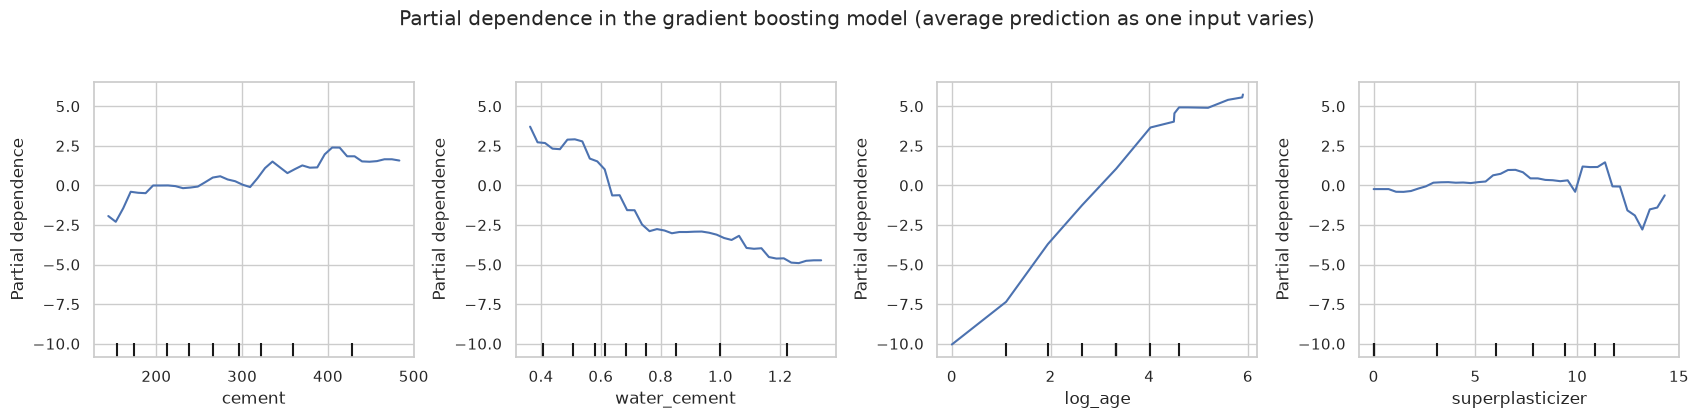

In [27]:
# Drawing partial dependence plots to see what the gradient boosting model has learned
gb_est, gb_feats = fitted["Gradient boosting"]
fig, axes = plt.subplots(1, 4, figsize=(17, 4))
PartialDependenceDisplay.from_estimator(gb_est, train[gb_feats], ["cement", "water_cement", "log_age", "superplasticizer"],
                                        ax=axes, grid_resolution=40)
plt.suptitle("Partial dependence in the gradient boosting model (average prediction as one input varies)", y=1.04)
plt.tight_layout(); plt.show()

The partial dependence plots line up with engineering knowledge: predicted strength falls as the water to cement ratio rises and climbs steadily with the log of age. Once the ratio and age are accounted for, cement on its own adds only a few MPa across its whole range, and superplasticizer has little effect apart from a dip at the highest doses where data is sparse. This agreement with known science is reassuring and suggests the model has learned sensible patterns rather than noise. It is important, though, to be careful about reading these curves as cause and effect, which is the subject of Part 3.

### 2.7 Summary of the comparison

In [28]:
# Pulling the main results together into one table
summary = pd.DataFrame({
    "grouped CV RMSE": cv_table["cv RMSE"],
    "test RMSE": test_table.loc[cv_table.index, "RMSE"],
    "test MAE": test_table.loc[cv_table.index, "MAE"],
    "test R2": test_table.loc[cv_table.index, "R2"],
})
summary.loc["Mean baseline"] = [np.nan, base_scores["RMSE"], base_scores["MAE"], base_scores["R2"]]
summary.round(3)

,grouped CV RMSE,test RMSE,test MAE,test R2
model,,,,
Linear (raw inputs),10.300,10.792,8.678,0.639
Linear (engineered inputs),6.945,7.436,5.605,0.829
Random forest,5.541,5.768,4.013,0.897
Gradient boosting,5.280,6.044,3.963,0.887
Mean baseline,NaN,18.016,14.476,-0.006


Nonlinear models clearly win. The two tree models cut the baseline error by about two thirds and nearly halve the error of the plain linear model, and they are statistically tied with each other. A linear model given well chosen engineered features closes much of the gap and remains a useful, transparent option, which shows how much value domain knowledge adds. But it cannot match the tree models because strength depends on interactions, for example the benefit of slag and fly ash appearing only at later ages. The weakest region for every model is high strength concrete, where errors are larger and biased downwards, so predictions above about 60 MPa should be treated with extra caution.

## Part 3. Does a predictive link between cement and strength prove what will happen if we change the mix?

No. A predictive association, however strong and however well validated, shows that knowing the cement content helps us guess the strength of mixes like the ones in this dataset. It does not on its own establish what would happen to strength if an engineer took a particular mix and changed the cement. The evidence from this dataset makes the point concretely.

### 3.1 The answer changes depending on what else is held fixed

In [29]:
# Estimating the cement coefficient with different sets of other variables in the regression
def cement_coef(cols):
    return sm.OLS(df["strength"], sm.add_constant(df[cols])).fit().params["cement"]

adjust_sets = {
    "cement only": ["cement"],
    "cement and age": ["cement", "age"],
    "cement, age and water": ["cement", "age", "water"],
    "all eight raw inputs": features_raw,
    "cement and log age, plus water to cement ratio": ["cement", "log_age", "water_cement"],
}
pd.DataFrame({"MPa gained per extra kg of cement": {k: cement_coef(v) for k, v in adjust_sets.items()}}).round(4)

,MPa gained per extra kg of cement
cement only,0.0762
cement and age,0.0722
"cement, age and water",0.0677
all eight raw inputs,0.1172
"cement and log age, plus water to cement ratio",0.0319


In [30]:
# Checking how cement moves together with the other ingredients
print("Correlation of cement with the other ingredients")
print(df[ingredients].corr()["cement"].drop("cement").round(2).to_string())

Correlation of cement with the other ingredients
slag               -0.30
fly_ash            -0.39
water              -0.06
superplasticizer    0.06
coarse_agg         -0.09
fine_agg           -0.25


The estimated effect of one extra kilogram of cement swings depending on which other variables are in the model, ranging from about 0.03 to about 0.12 MPa per kg in the regressions above, a fourfold difference. When the water to cement ratio is included, most of what looked like a cement effect is absorbed by the ratio, which is exactly what Abrams' law would predict, and it would change again if we added variables that are not in the data. Each of these numbers answers a different question. There is no single "cement effect" waiting to be read off the data, because cement does not vary on its own in this dataset: it moves together with slag and fly ash (which replace it), with fine aggregate, and with the choices each laboratory made.

### 3.2 Adding cement means taking something else out

In [31]:
# Here I am taking a typical 28 day mix, raising the cement by 50 kg in three physically different ways,
# and asking the gradient boosting model what it predicts in each case
base_mix = train[train["age"] == 28][features_raw].median().to_frame().T
base_mix["slag"] = 100.0  # making sure the reference mix has some slag that I can swap out

scenario_a = base_mix.copy(); scenario_a["cement"] += 50                              # only adding cement, so the mix gets heavier
scenario_b = base_mix.copy(); scenario_b["cement"] += 50; scenario_b["slag"] -= 50    # swapping slag for cement, so the binder total stays the same
scenario_c = base_mix.copy(); scenario_c["cement"] += 50; scenario_c["fine_agg"] -= 50  # swapping sand for cement

scen = pd.concat([base_mix, scenario_a, scenario_b, scenario_c], ignore_index=True)
scen.index = ["reference mix", "add 50 kg cement only", "swap 50 kg slag for cement", "swap 50 kg sand for cement"]
scen_feat = add_features(scen)
scen["predicted strength (MPa)"] = gb_est.predict(scen_feat[gb_feats])
scen["change vs reference"] = scen["predicted strength (MPa)"] - scen.loc["reference mix", "predicted strength (MPa)"]
scen.round(1)

,cement,slag,fly_ash,water,superplasticizer,coarse_agg,fine_agg,age,predicted strength (MPa),change vs reference
reference mix,260.9,100.0,78.0,185.7,7.8,955.1,770.1,28.0,36.0,0.0
add 50 kg cement only,310.9,100.0,78.0,185.7,7.8,955.1,770.1,28.0,45.0,9.0
swap 50 kg slag for cement,310.9,50.0,78.0,185.7,7.8,955.1,770.1,28.0,38.2,2.2
swap 50 kg sand for cement,310.9,100.0,78.0,185.7,7.8,955.1,720.1,28.0,43.6,7.6


The same "50 kg more cement" gives a predicted gain of about 9 MPa if the cement is simply added, about 7.6 MPa if it replaces sand, but only about 2 MPa if it replaces slag. The change depends heavily on what it replaces. In real concrete a cubic metre has a fixed volume (Part 1 showed the total mass sits in a narrow band), so you cannot add cement without changing something else. The model can only tell us what strength is typical of mixes that look like each of these rows. It cannot tell us which of these changes an engineer should expect in practice, because that depends on how the mix is actually redesigned.

### 3.3 Why the association is not proof

Pulling the evidence together, there are five reasons the predictive association between cement and strength should not be read as proof of what an intervention would do.

1. The data is observational. Yeh (1998) gathered results from 17 different sources. Nobody randomly assigned cement levels. Laboratories that used more cement may also have used better aggregates, stricter curing or a stronger grade of cement, none of which are recorded. Any of these could make high cement mixes stronger for reasons other than the cement itself. This is classic confounding.
2. Ingredients move together. Section 3.1 showed the cement coefficient shifts with the choice of other variables, and cement is negatively correlated with slag and fly ash because they substitute for it. The data cannot separate "more cement" from "less of what it replaced".
3. The mix is constrained. Because a cubic metre has a fixed volume, "increase cement while holding everything else constant", which is how a regression coefficient or a partial dependence plot is usually read, describes a mix that may not be physically possible. Section 3.2 showed the predicted outcome depends on what is removed.
4. Models are tuned to predict, not to explain. Gradient boosting was chosen because it minimises error on unseen recipes. It is free to use any variable that helps, including ones that merely travel with the true causes. Its partial dependence curve for cement is a summary of the model, not a measurement of physics.
5. Predictions outside the observed range are guesses. The data contains no cement above 540 kg, and the model's curve is flat beyond the edges of what it has seen. Very high cement mixes can also suffer from problems such as heat of hydration and shrinkage cracking, which this data cannot reveal.

That said, the association is not meaningless. Decades of controlled laboratory work, beginning with Abrams (1918), give strong independent reasons to believe that cement content and the water to cement ratio do causally affect strength, and our model agrees in direction. So the honest conclusion is that the model is consistent with established causal knowledge, but the data alone does not prove it, and it does not give a reliable size for the effect of a specific change.

To find out what would really happen if a mix were changed, the right tool is a designed experiment: cast batches that differ only in the planned way (for example, a fixed set of cement levels with water to cement ratio, aggregates, cement type and curing conditions controlled), with replicates, and test them. The model is useful for screening candidate mixes and for deciding which experiments are worth running, but the final decision on a structural mix should rest on physical testing.

## References

Abrams, D. A. (1918). Design of concrete mixtures. Bulletin 1, Structural Materials Research Laboratory, Lewis Institute, Chicago.

Breiman, L. (2001). Random forests. Machine Learning, 45(1), 5 to 32.

Friedman, J. H. (2001). Greedy function approximation: a gradient boosting machine. Annals of Statistics, 29(5), 1189 to 1232.

Pedregosa, F. and colleagues (2011). Scikit learn: machine learning in Python. Journal of Machine Learning Research, 12, 2825 to 2830.

Seabold, S. and Perktold, J. (2010). Statsmodels: econometric and statistical modeling with Python. Proceedings of the 9th Python in Science Conference.

Yeh, I. C. (1998). Modeling of strength of high performance concrete using artificial neural networks. Cement and Concrete Research, 28(12), 1797 to 1808.

Dataset: Concrete Compressive Strength data set, UCI Machine Learning Repository, provided with the assignment as `Concrete_Data.csv`.